In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

from donnees import charger_raca, nettoyer_raca, reechantillonner_raca
from evaluation import scores_regression

serie = reechantillonner_raca(nettoyer_raca(charger_raca()))
dl = serie[serie["application"] == "Download"].copy()
dl["debit"] = dl["DL_bitrate"] / 1000                     # kbit/s -> Mbit/s

# répartition des TRACES (pas des lignes) : 14 entraînement, 3 validation, 4 test
traces = sorted(dl["trace"].unique())
np.random.default_rng(0).shuffle(traces)
groupes = {"entr": traces[:14], "val": traces[14:17], "test": traces[17:]}

for nom, liste in groupes.items():
    part = dl[dl["trace"].isin(liste)]
    print(nom, len(liste), "traces,", len(part), "secondes, débit moyen", round(part["debit"].mean(), 1))

VARIABLES = ["debit", "RSRP", "RSRQ", "SNR", "CQI"]
entr_df = dl[dl["trace"].isin(groupes["entr"])]
moy, ect = entr_df[VARIABLES].mean(), entr_df[VARIABLES].std()   # appris sur l'entraînement seul
print(dl[VARIABLES].isna().mean().round(3))

entr 14 traces, 29609 secondes, débit moyen 46.9
val 3 traces, 5889 secondes, débit moyen 38.3
test 4 traces, 10267 secondes, débit moyen 45.6
debit    0.000
RSRP     0.099
RSRQ     0.102
SNR      0.099
CQI      0.099
dtype: float64


In [2]:
from sequences import fenetres, entrainer_reseau, predire

W, h = 10, 1
D = {nom: fenetres(dl[dl["trace"].isin(liste)], VARIABLES, moy, ect, W=W, h=h)
     for nom, liste in groupes.items()}
X_entr, y_entr, _, _ = D["entr"]
X_val, y_val, _, _ = D["val"]
X_test, y_test, ev_test, pers_test = D["test"]
print(X_entr.shape, X_val.shape, X_test.shape)
print("part des cibles de test évaluables :", ev_test.mean().round(3))

(29469, 10, 6) (5859, 10, 6) (10227, 10, 6)
part des cibles de test évaluables : 0.85


                MAE    RMSE     R2
persistance  15.328  35.677  0.738
xgb          15.885  32.723  0.780


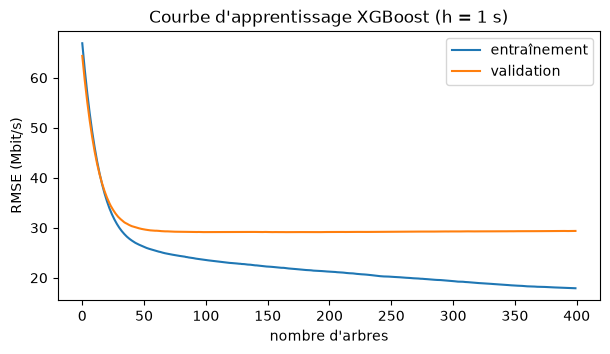

In [3]:
resultats = {}
resultats["persistance"] = scores_regression(y_test[ev_test], pers_test[ev_test])

aplatir = lambda X: X.reshape(len(X), -1)          # (n, 10, 6) -> (n, 60)
xgb = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                   n_jobs=-1, random_state=0, eval_metric="rmse")
xgb.fit(aplatir(X_entr), y_entr,
        eval_set=[(aplatir(X_entr), y_entr), (aplatir(X_val), y_val)], verbose=False)
resultats["xgb"] = scores_regression(y_test[ev_test], xgb.predict(aplatir(X_test))[ev_test])
print(pd.DataFrame(resultats).T.round(3))

courbe = xgb.evals_result()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(courbe["validation_0"]["rmse"], label="entraînement")
ax.plot(courbe["validation_1"]["rmse"], label="validation")
ax.set_xlabel("nombre d'arbres"); ax.set_ylabel("RMSE (Mbit/s)")
ax.set_title("Courbe d'apprentissage XGBoost (h = 1 s)"); ax.legend()
fig.savefig("../results/figures/raca_courbe_xgb_h1.png", dpi=150, bbox_inches="tight")
plt.show()

paramètres : 5153
42 époques, meilleure à l'époque 34, 116 s
                MAE    RMSE     R2
persistance  15.328  35.677  0.738
xgb          15.885  32.723  0.780
lstm         15.310  30.499  0.809


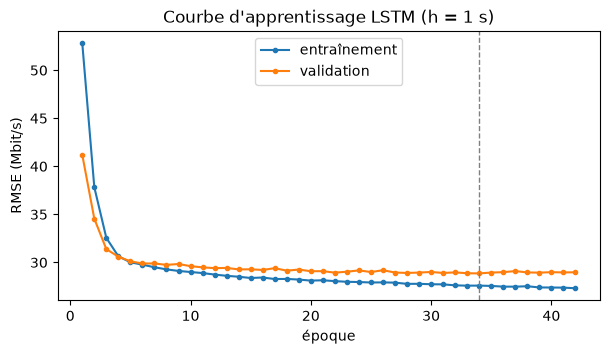

In [4]:
class ReseauLSTM(nn.Module):
    def __init__(self, n_variables, n_cachees=32):
        super().__init__()
        self.lstm = nn.LSTM(n_variables, n_cachees, batch_first=True)
        self.sortie = nn.Linear(n_cachees, 1)

    def forward(self, x):                  # x : (lot, W, variables)
        etats, _ = self.lstm(x)            # etats : (lot, W, n_cachees), un état par seconde
        return self.sortie(etats[:, -1, :])   # état de la dernière seconde -> débit

torch.manual_seed(0)
lstm = ReseauLSTM(X_entr.shape[2])
print("paramètres :", sum(p.numel() for p in lstm.parameters()))
lstm, hist_lstm = entrainer_reseau(lstm, X_entr, y_entr, X_val, y_val)
resultats["lstm"] = scores_regression(y_test[ev_test], predire(lstm, X_test)[ev_test])
print(pd.DataFrame(resultats).T.round(3))

hist = pd.DataFrame(hist_lstm)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(hist["epoque"], np.sqrt(hist["perte_entr"]) * 100, marker="o", ms=3, label="entraînement")
ax.plot(hist["epoque"], np.sqrt(hist["perte_val"]) * 100, marker="o", ms=3, label="validation")
ax.axvline(hist["perte_val"].idxmin() + 1, color="grey", ls="--", lw=1)   # meilleure époque
ax.set_xlabel("époque"); ax.set_ylabel("RMSE (Mbit/s)")
ax.set_title("Courbe d'apprentissage LSTM (h = 1 s)"); ax.legend()
fig.savefig("../results/figures/raca_courbe_lstm_h1.png", dpi=150, bbox_inches="tight")
plt.show()

h = 1 s : XGBoost arrêté à 105 arbres
42 époques, meilleure à l'époque 34, 112 s
h = 5 s : XGBoost arrêté à 53 arbres
16 époques, meilleure à l'époque 8, 39 s
h = 10 s : XGBoost arrêté à 64 arbres
16 époques, meilleure à l'époque 8, 37 s
 horizon      modele    MAE   RMSE     R2
       1 persistance 15.328 35.677  0.738
       1         xgb 15.606 32.359  0.784
       1        lstm 15.310 30.499  0.809
       5 persistance 38.150 72.565 -0.084
       5         xgb 29.631 50.395  0.477
       5        lstm 33.021 53.963  0.401
      10 persistance 41.396 76.363 -0.200
      10         xgb 33.601 56.104  0.352
      10        lstm 34.930 56.843  0.335


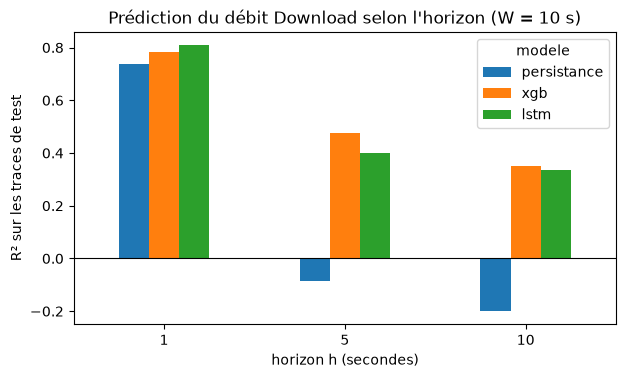

In [5]:
lignes, modeles_lstm, historiques = [], {}, {}
for h in [1, 5, 10]:
    D = {nom: fenetres(dl[dl["trace"].isin(liste)], VARIABLES, moy, ect, W=10, h=h)
         for nom, liste in groupes.items()}
    Xe, ye, _, _ = D["entr"]
    Xv, yv, _, _ = D["val"]
    Xt, yt, evt, pt = D["test"]

    xgb_h = XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=6, n_jobs=-1,
                         random_state=0, early_stopping_rounds=30)
    xgb_h.fit(aplatir(Xe), ye, eval_set=[(aplatir(Xv), yv)], verbose=False)
    print(f"h = {h} s : XGBoost arrêté à {xgb_h.best_iteration + 1} arbres")

    torch.manual_seed(0)
    lstm_h, historiques[h] = entrainer_reseau(ReseauLSTM(Xe.shape[2]), Xe, ye, Xv, yv)
    modeles_lstm[h] = lstm_h

    for nom, pred in [("persistance", pt), ("xgb", xgb_h.predict(aplatir(Xt))),
                      ("lstm", predire(lstm_h, Xt))]:
        lignes.append({"horizon": h, "modele": nom, **scores_regression(yt[evt], pred[evt])})

res = pd.DataFrame(lignes).round(3)
res.to_csv("../results/tables/raca_horizons_test.csv", index=False)
print(res.to_string(index=False))

tab = res.pivot(index="horizon", columns="modele", values="R2")[["persistance", "xgb", "lstm"]]
ax = tab.plot.bar(figsize=(7, 3.8), rot=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("horizon h (secondes)"); ax.set_ylabel("R² sur les traces de test")
ax.set_title("Prédiction du débit Download selon l'horizon (W = 10 s)")
ax.figure.savefig("../results/figures/raca_r2_horizons.png", dpi=150, bbox_inches="tight")
plt.show()

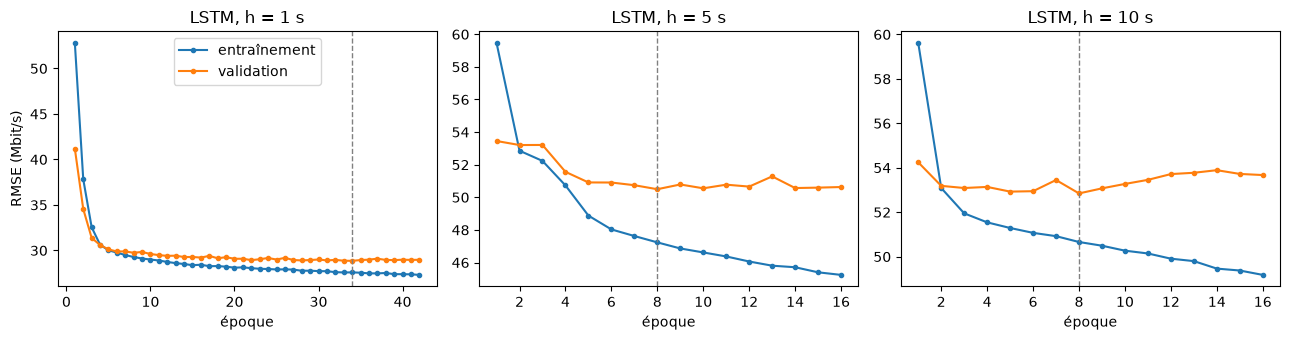

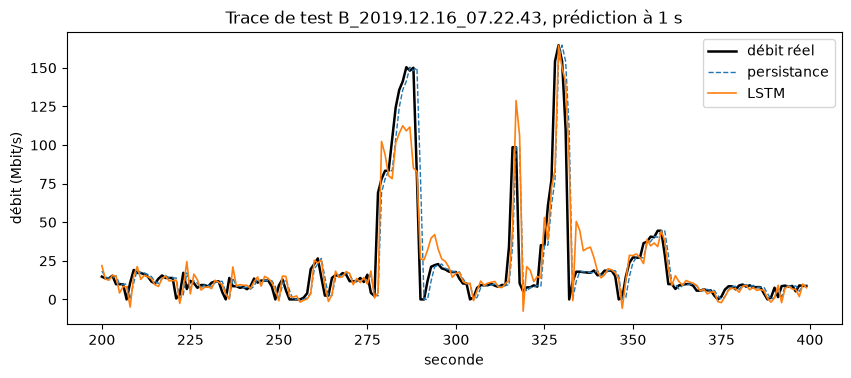

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, h in zip(axes, [1, 5, 10]):
    hi = pd.DataFrame(historiques[h])
    ax.plot(hi["epoque"], np.sqrt(hi["perte_entr"]) * 100, marker="o", ms=3, label="entraînement")
    ax.plot(hi["epoque"], np.sqrt(hi["perte_val"]) * 100, marker="o", ms=3, label="validation")
    ax.axvline(hi["perte_val"].idxmin() + 1, color="grey", ls="--", lw=1)
    ax.set_title(f"LSTM, h = {h} s"); ax.set_xlabel("époque")
axes[0].set_ylabel("RMSE (Mbit/s)"); axes[0].legend()
fig.tight_layout()
fig.savefig("../results/figures/raca_courbes_lstm_horizons.png", dpi=150, bbox_inches="tight")
plt.show()

nom = sorted(groupes["test"])[0]
Xa, ya, _, pa = fenetres(dl[dl["trace"] == nom], VARIABLES, moy, ect, W=10, h=1)
debut, fin = 200, 400
s = np.arange(debut, fin)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(s, ya[debut:fin], color="black", lw=1.8, label="débit réel")
ax.plot(s, pa[debut:fin], lw=1, ls="--", label="persistance")
ax.plot(s, predire(lstm, Xa[debut:fin]), lw=1.2, label="LSTM")
ax.set_xlabel("seconde"); ax.set_ylabel("débit (Mbit/s)")
ax.set_title(f"Trace de test {nom}, prédiction à 1 s"); ax.legend()
fig.savefig("../results/figures/raca_trace_test_h1.png", dpi=150, bbox_inches="tight")
plt.show()